In [326]:
# Tarefa 2
# Cap. 13 Seinfeld e Pandis - Dinâmica de populações de aerossóis
# Aluno: Thiago Honório Leandro

In [327]:
import numpy as np
import matplotlib.pyplot as plt

In [328]:
# Constantes e Parâmetros iniciais do exemplo do livro

T = 298.0            # Temperatura (K)
R = 82.057           # (cm^3 atm mol^-1 K^-1)
rho_p = 1.0          # Densidade da partícula (água) (g/cm^3)
Di = 0.1             # Coeficiente de difusão (cm^2/s)
delta_p = 1e-9       # supersaturação (p_i - p_eq,i) (atm)
# Mi = 100            # Massa molar (g/mol) - Exemplo livro
# Mi = 18             # Massa molar utilizada na simulação (g/mol)

# Calculo da constante A da lei de crescimento I_D = A/D_p (Eq. 13.13)
def A_um2s(Mi, delta_p=1e-9, Di=Di, T=T, rho_p=rho_p):
    A_cm2s = 4.0 * Di * Mi * delta_p / (R * T * rho_p)
    return A_cm2s * 1e8   # cm^2/s -> µm^2/s
    

In [381]:
# Distribuição log-normal no(Dp) (Eq. 13.26) em cm^-3 µm^-1

N0 = 1000.0         # Concentração numérica total (cmˆ-3) -> valor inicial adotado para escala do gráfico 
Dpg = 0.2           # Diâmetro geométrico médio inicial (µm)
sigma_g = 1.5       # Desvio padrão geométrico     

def n_lognormal(Dp, N0=N0, Dpg=Dpg, sigma_g=sigma_g):
    Dp = np.asarray(Dp, dtype=float)
    return (N0 / (np.sqrt(2.0 * np.pi) * Dp * np.log(sigma_g))
            * np.exp(-(np.log(Dp / Dpg))**2
                     / (2.0 * np.log(sigma_g)**2)))


In [330]:
# Solução Analítica n(Dp, t) (Eq. 13.27)
def n_condensacao(Dp, t_s, A, N0=N0, Dpg=Dpg, sigma_g=sigma_g):
    Dp = np.asarray(Dp, dtype=float)
    n = np.zeros_like(Dp, dtype=float)
    val = Dp**2 - 2.0 * A * t_s   # Eq. 13.24
    mask = val > 0.0
    Dp0 = np.sqrt(val[mask])
    n[mask] = (Dp[mask] / val[mask]
               * N0 / (np.sqrt(2.0 * np.pi) * np.log(sigma_g))
               * np.exp(-(np.log(Dp0 / Dpg))**2
                        / (2.0 * np.log(sigma_g)**2)))
    return n


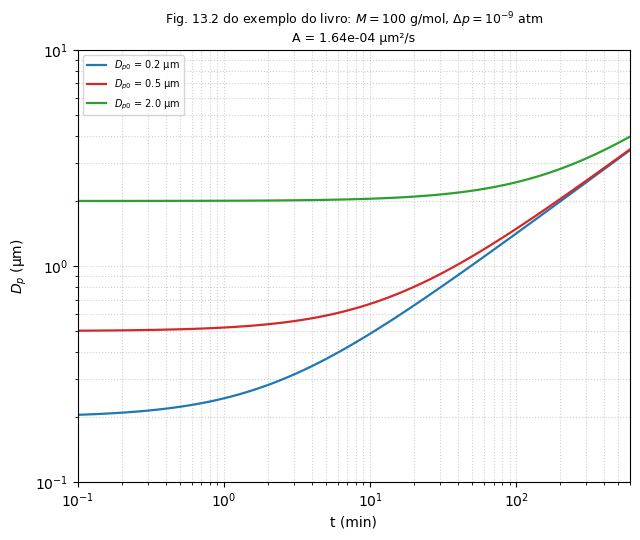

In [331]:
# Esboçando as curvas características

t_min = np.logspace(-1, 3, 100)   # 0.1 a 100 min
t_s = t_min * 60.0                # s

Dp0_list = [0.2, 0.5, 2.0]        # µm
estilos = ['-', '-', '-']
cores = ['C0', 'C3', 'C2']

def plot_caracteristicas(ax, Mi, delta_p, titulo=None):
    A = A_um2s(Mi=Mi, delta_p=delta_p)
    for Dp0, ls, cor in zip(Dp0_list, estilos, cores):
        Dp_t = np.sqrt(Dp0**2 + 2.0 * A * t_s)
        ax.plot(t_min, Dp_t, ls=ls, color=cor, lw=1.6,
                label=f'$D_{{p0}}$ = {Dp0} µm')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(0.1, 600)
    ax.set_ylim(0.1, 10)
    ax.set_xlabel('t (min)')
    ax.set_ylabel('$D_p$ (µm)')
    if titulo is None:
        titulo = (r'$M=%g$ g/mol, $\Delta p=%.1e$ atm'
                  % (M, delta_p))
    ax.set_title(titulo + '\n' + r'A = %.2e µm²/s' % A,
                 fontsize=9)
    ax.grid(True, which='both', ls=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=7)

# Gráfico (a) - reprodução da Fig. 13.2 do exemplo do livro
# Para: M = 100 g/mol, delta p = 1e-9 atm

figA, axA = plt.subplots(figsize=(6.5, 5.5))
plot_caracteristicas(axA, Mi=100.0, delta_p=1e-9,
                     titulo='Fig. 13.2 do exemplo do livro: '
                            r'$M=100$ g/mol, $\Delta p=10^{-9}$ atm')
plt.tight_layout()
plt.savefig('fig13_2_livro.png', dpi=300)
plt.show()


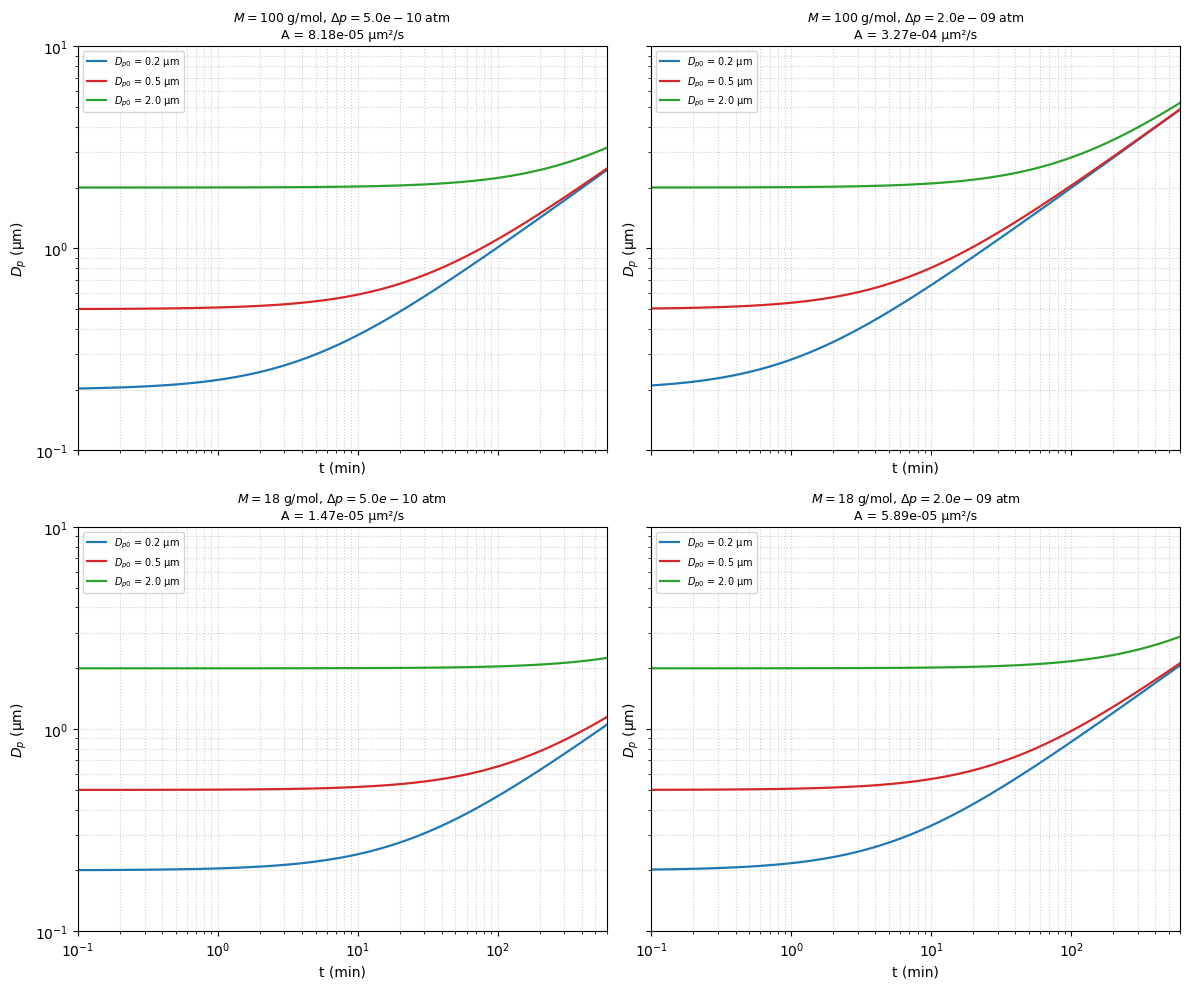

In [332]:
# Gráfico (b) - simulações

combinacoes = [
    (100.0, 5e-10),
    (100.0, 2e-9),
    (18.0,  5e-10),
    (18.0,  2e-9),
]

figB, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (M, dp) in zip(axes, combinacoes):
    plot_caracteristicas(ax, Mi=M, delta_p=dp)

plt.tight_layout()
plt.savefig('fig13_2_simulacoes_4.png', dpi=300)
plt.show()

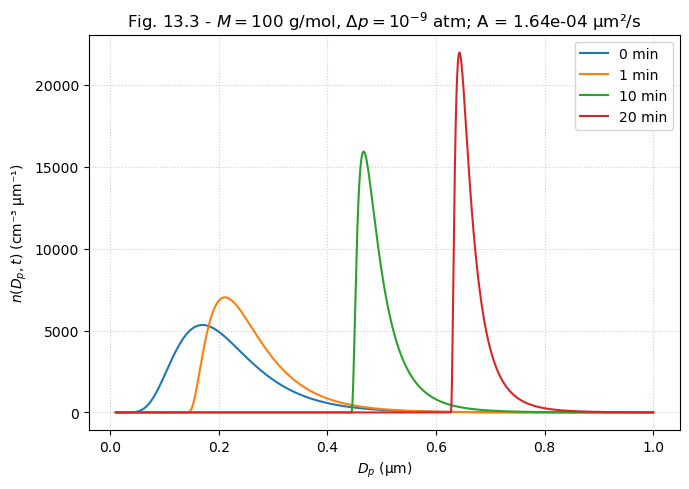

In [382]:
# Evolução da distribuição log-normal
# Figura 13.3 do livro para M=100 g/mol e delta p = 1e-9 atm

Dp_grid = np.linspace(0.01, 1.0, 3000)   # um
tempos_min = [0, 1, 10, 20]              # min
tempos_s = [tm * 60.0 for tm in tempos_min]

M1, dp1 = 100.0, 1e-9
A1 = A_um2s(Mi=M1, delta_p=dp1)

fig1, ax1 = plt.subplots(figsize=(7, 5))
for tm_s, tm in zip(tempos_s, tempos_min):
    n = n_condensacao(Dp_grid, tm_s, A1)
    ax1.plot(Dp_grid, n, label=f'{tm} min')

ax1.set_xlabel('$D_p$ (µm)')
ax1.set_ylabel('$n(D_p, t)$ (cm⁻³ µm⁻¹)')
ax1.set_title('Fig. 13.3 - $M=100$ g/mol, '
              r'$\Delta p=10^{-9}$ atm; A = %.2e µm²/s' % A1)

ax1.grid(True, ls=':', alpha=0.6)
ax1.legend()
plt.tight_layout()
plt.savefig('fig13_3_M100_dp1e-9.png', dpi=300)
plt.show()


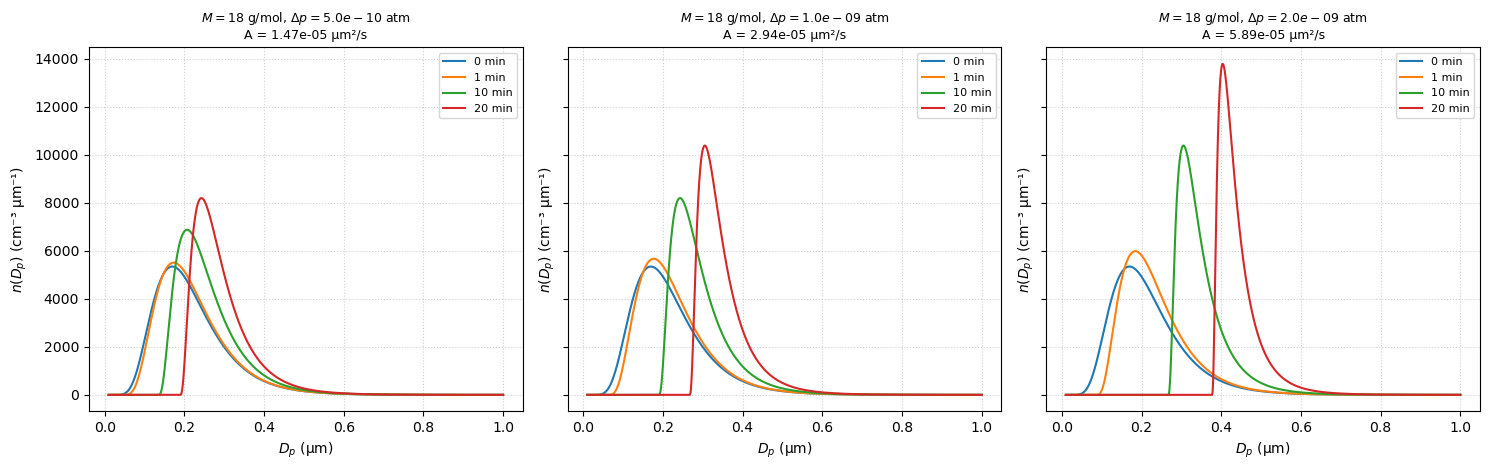

In [344]:
# Item 2 Simulações 
# Fazendo para M=18 g/mol e delta p = 5e-10, 1e-9 e 2e-9

M2 = 18.0
dp_list = [5e-10, 1e-9, 2e-9]
cores = ['C0', 'C1', 'C2']
estilos = ['-', '--', '-.']

fig3, axes3 = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

for ax, dp in zip(axes3, dp_list):
    A = A_um2s(Mi=M2, delta_p=dp)
    for tm_s, tm in zip(tempos_s, tempos_min):
        n = n_condensacao(Dp_grid, tm_s, A)
        ax.plot(Dp_grid, n, label=f'{tm} min')
    ax.set_xlabel('$D_p$ (µm)')
    ax.set_ylabel('$n(D_p)$ (cm⁻³ µm⁻¹)')
    ax.set_title(r'$M=18$ g/mol, $\Delta p=%.1e$ atm' % dp
                 + '\n' + r'A = %.2e µm²/s' % A, fontsize=9)
    ax.grid(True, ls=':', alpha=0.6)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig13_3_M18_paineis.png', dpi=300)
plt.show()

In [348]:
# Impressão dos valores de A

print('Valores de A (µm²/s):')
for M in [100.0, 18.0]:
    for dp in dp_list:
        A = A_um2s(Mi=M, delta_p=dp)
        print(f'  M={M:5.1f} g/mol, dp={dp:.1e} atm -> '
              f'A = {A:.3e} µm²/s')

Valores de A (µm²/s):
  M=100.0 g/mol, dp=5.0e-10 atm -> A = 8.179e-05 µm²/s
  M=100.0 g/mol, dp=1.0e-09 atm -> A = 1.636e-04 µm²/s
  M=100.0 g/mol, dp=2.0e-09 atm -> A = 3.272e-04 µm²/s
  M= 18.0 g/mol, dp=5.0e-10 atm -> A = 1.472e-05 µm²/s
  M= 18.0 g/mol, dp=1.0e-09 atm -> A = 2.944e-05 µm²/s
  M= 18.0 g/mol, dp=2.0e-09 atm -> A = 5.889e-05 µm²/s


Item 3 - M=100.0 g/mol, dp=1.0e-09 atm
  A = 1.636e-04 um2/s
  t* = 1956.2 s = 32.60 min


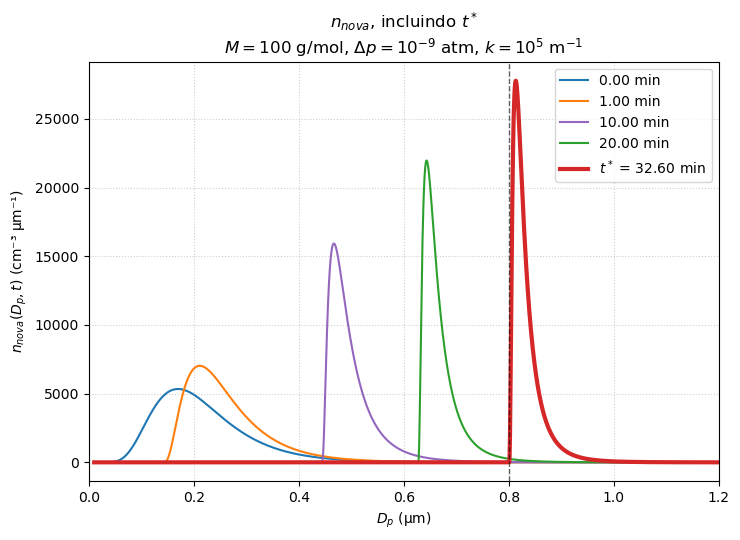

In [380]:
# Item 3 - n_nova no estilo da Fig. 13.3
# Incluindo t* (instante em que a frente atinge 0.8 um)
# M = 100 g/mol, delta_p = 1e-9 atm
# n_nova = n - k*x para Dp >= 0.8 um, k = 1e5 m^-1

# Parametros do item 3

k_item3 = 1e5          # m^-1
x_limiar = 0.8         # um

M3, dp3 = 100.0, 1e-9
A3 = A_um2s(Mi=M3, delta_p=dp3)

t_estrela_s = x_limiar**2 / (2.0 * A3)
t_estrela_min = t_estrela_s / 60.0

print(f'Item 3 - M={M3} g/mol, dp={dp3:.1e} atm')
print(f'  A = {A3:.3e} um2/s')
print(f'  t* = {t_estrela_s:.1f} s = {t_estrela_min:.2f} min')


def aplica_item3(Dp, n, k=k_item3, x_limiar=x_limiar, truncar=True):
    Dp = np.asarray(Dp, dtype=float)
    n_nova = n.copy()
    mask = Dp >= x_limiar
    x_m = Dp[mask] * 1e-6          # um -> m
    n_nova[mask] = n[mask] - k * x_m
    if truncar:
        n_nova = np.maximum(n_nova, 0.0)
    return n_nova

# Tempos incluindo t*
# t = 0, 1, 10, 20, t* (min)

tempos_min = [0.0, 1.0, 10.0, 20.0, t_estrela_min]
tempos_s = [tm * 60.0 for tm in tempos_min]

# Rotulos e estilos: t* em destaque
rotulos = [f'{tm:.2f} min' for tm in tempos_min]
rotulos[4] = f'$t^*$ = {t_estrela_min:.2f} min'
estilos = ['-', '-', '-', '-', '-']
cores = ['C0', 'C1', 'C4', 'C2', 'C3']   # t* em C3 (vermelho)
larguras = [1.5, 1.5, 1.5, 1.5, 3.0]     # t* mais grossa

Dp_grid = np.linspace(0.01, 1.2, 3000)   # um


# Grafico unico com n_nova, incluindo t*

fig, ax = plt.subplots(figsize=(7.5, 5.5))

for tm_s, rot, cor, lw in zip(tempos_s, rotulos, cores, larguras):
    n = n_condensacao(Dp_grid, tm_s, A3)
    n_nova = aplica_item3(Dp_grid, n)
    ax.plot(Dp_grid, n_nova, '-', color=cor, lw=lw, label=rot)

ax.axvline(x_limiar, color='k', ls='--', lw=1.0, alpha=0.6)
ax.set_xlabel('$D_p$ (µm)')
ax.set_ylabel('$n_{nova}(D_p, t)$ (cm⁻³ µm⁻¹)')
ax.set_title('$n_{nova}$, '
             'incluindo $t^*$\n'
             r'$M=100$ g/mol, $\Delta p=10^{-9}$ atm, '
             r'$k=10^{5}$ m$^{-1}$')
ax.grid(True, ls=':', alpha=0.6)
ax.legend()
ax.set_xlim(0, 1.2)

plt.tight_layout()
plt.savefig('item3_nnova_unico_com_tstar.png', dpi=300)
plt.show()
